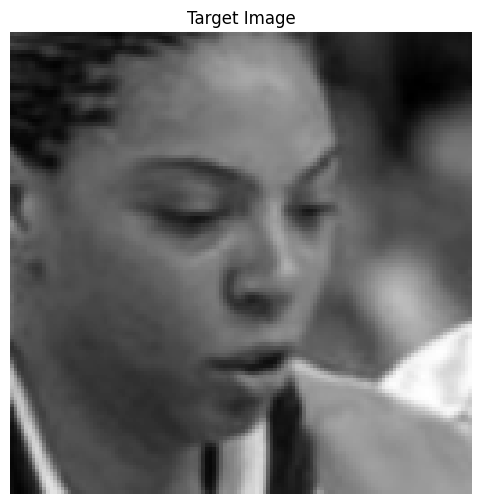

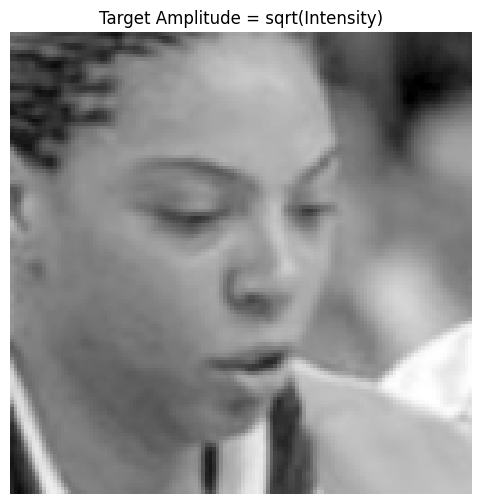

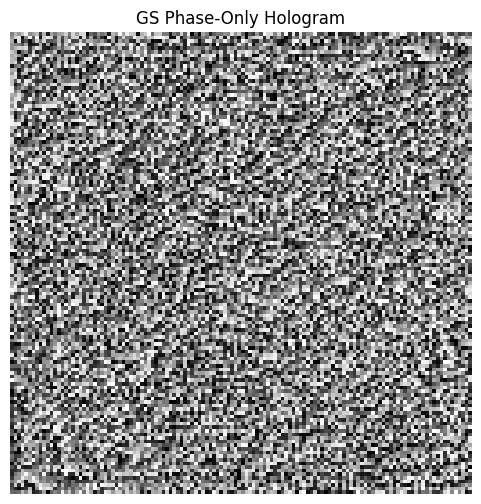

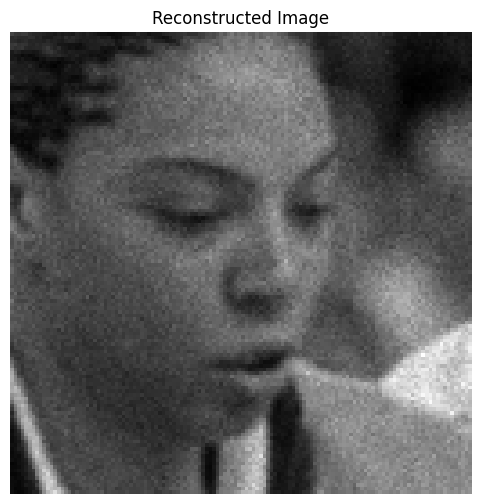

GS hologram generated successfully!
Iterations: 50
Saved:
output/GS_phase_hologram.png
output/GS_reconstructed.png


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
image_path = "images.jpg"

img = Image.open(image_path).convert("L")

# Initial computational resolution
image_size = (128, 128)

img = img.resize(image_size)

image = np.array(img, dtype=np.float64)

# Normalize intensity
target_intensity = image / 255.0
target_amplitude = np.sqrt(target_intensity)

initial_phase = np.zeros_like(target_amplitude)


target_field = (
    target_amplitude *
    np.exp(1j * initial_phase)
)

iterations = 50

field = target_field.copy()


for iteration in range(iterations):
    hologram_field = np.fft.fft2(field)
    hologram_phase = np.angle(hologram_field)

    hologram_field = np.exp(1j * hologram_phase)
    reconstructed_field = np.fft.ifft2(
        hologram_field
    )
    reconstructed_phase = np.angle(
        reconstructed_field
    )

    field = (
        target_amplitude *
        np.exp(1j * reconstructed_phase)
    )

final_hologram_phase = np.angle(
    np.fft.fft2(field)
)

phase_hologram = np.exp(
    1j * final_hologram_phase
)

reconstructed = np.fft.ifft2(
    phase_hologram
)

reconstructed_intensity = (
    np.abs(reconstructed) ** 2
)

reconstructed_display = (
    reconstructed_intensity -
    reconstructed_intensity.min()
) / (
    reconstructed_intensity.max() -
    reconstructed_intensity.min() +
    1e-12
)


phase_display = (
    final_hologram_phase + np.pi
) / (2 * np.pi)

plt.figure(figsize=(6, 6))

plt.imshow(
    image,
    cmap="gray"
)

plt.title("Target Image")

plt.axis("off")

plt.show()


plt.figure(figsize=(6, 6))

plt.imshow(
    target_amplitude,
    cmap="gray"
)

plt.title("Target Amplitude = sqrt(Intensity)")

plt.axis("off")

plt.show()


plt.figure(figsize=(6, 6))

plt.imshow(
    phase_display,
    cmap="gray"
)

plt.title("GS Phase-Only Hologram")

plt.axis("off")

plt.show()


plt.figure(figsize=(6, 6))

plt.imshow(
    reconstructed_display,
    cmap="gray"
)

plt.title("Reconstructed Image")

plt.axis("off")

plt.show()


# ============================================================
# 9. SAVE RESULTS
# ============================================================

os.makedirs("output", exist_ok=True)

Image.fromarray(
    (phase_display * 255).astype(np.uint8)
).save(
    "output/GS_phase_hologram.png"
)

Image.fromarray(
    (reconstructed_display * 255).astype(np.uint8)
).save(
    "output/GS_reconstructed.png"
)

print("GS hologram generated successfully!")
print("Iterations:", iterations)
print("Saved:")
print("output/GS_phase_hologram.png")
print("output/GS_reconstructed.png")

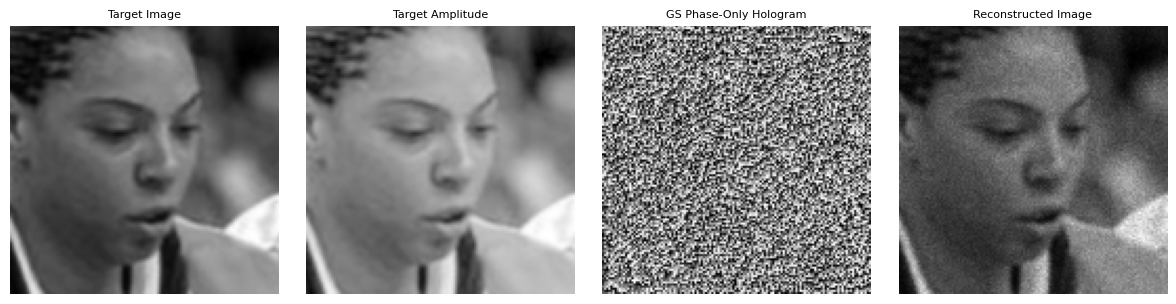

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

images = [
    image,
    target_amplitude,
    phase_display,
    reconstructed_display
]

titles = [
    "Target Image",
    "Target Amplitude",
    "GS Phase-Only Hologram",
    "Reconstructed Image"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray")
    ax.set_title(title, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()